# First model

Predict one of eight topic labels from an article's title and body.

The training file is `data/clean/articles_single.csv`. It keeps articles with at least 100 words and exactly one label from the grouping in `topic_grouping.md`. Syndicated copies of the same story (same title or same first 300 characters of the body) are merged into one article before labelling, so a story cannot sit in both the training and the test split. The original export and the file that still contains multi-label articles are left unchanged.

This notebook fits one baseline: TF–IDF features and logistic regression. Run it from the project directory after `clean_dataset.py` and `select_single_label.py`.

## Load the single-label articles

Each row is one article. `label` is the class to predict. `topics` still holds the original fine-grained tags, joined with `|`, so the mapping can be checked later.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline

DATA_PATH = Path("data/clean/articles_single.csv")
RANDOM_STATE = 42

articles = pd.read_csv(DATA_PATH)
articles["body_words"] = articles["body"].fillna("").str.split().str.len()

print(f"Rows: {len(articles):,}")
print(f"Columns: {list(articles.columns)}")
print(f"Shortest body: {articles['body_words'].min()} words")
print(f"Labels with more than one class: {(articles['label'].str.contains('|', regex=False)).sum()}")

Rows: 12,634
Columns: ['uuid', 'title', 'published_at', 'publisher', 'original_url', 'topics', 'label', 'body', 'body_words']
Shortest body: 100 words
Labels with more than one class: 0


## Class sizes

Sports is about a third of the set, and politics is the smallest class. Accuracy alone would reward predicting the large classes, so the model is judged with macro-F1 as well as accuracy.

In [2]:
class_counts = articles["label"].value_counts()
class_share = (class_counts / len(articles) * 100).round(1)
pd.DataFrame({"articles": class_counts, "percent": class_share})

,articles,percent
label,,
sports,3993,31.6
technology,1584,12.5
science_nature,1566,12.4
entertainment_culture,1454,11.5
lifestyle,1405,11.1
business_finance,1009,8.0
health,948,7.5
politics_society,675,5.3


## Text given to the model

The classifier reads the title and the body as one string. The title is short, but it usually names the subject of the article.

`clean_dataset.py` has already removed URLs, email addresses, emoji, `@handles`, and HTML entities, so this part is final gate, not crucial.

In [3]:
articles["text"] = (
    articles["title"].fillna("").str.strip()
    + "\n"
    + articles["body"].fillna("").str.strip()
)

print(articles.loc[0, "label"])
print(articles.loc[0, "text"][:400])

sports
WATCH | Bafana receive hearty welcome at OR Tambo International Airport
Bafana Bafana have received a warm welcome from cheering fans and dignitaries at OR Tambo International Airport. Supporters are happy with the team for making history at the FIFA World Cup by reaching the round of 32 stage. Bafana Bafana return to the country after losing to Canada at the tournament. Hundreds of fans braved th


## Train, validation, and test split

The split is 70% train, 15% validation, and 15% test. It is stratified on `label`, so each class keeps the same share in every part. `random_state=42` makes the split repeatable.

The vectorizer and the classifier are fit on the training part only. Validation is for checking this first model. The test part is scored once, after that.

In [4]:
train_df, held_out_df = train_test_split(
    articles,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=articles["label"],
)
val_df, test_df = train_test_split(
    held_out_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=held_out_df["label"],
)

split_sizes = pd.Series(
    {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}
)
split_sizes

train         8843
validation    1895
test          1896
dtype: int64

## TF–IDF features and logistic regression

Each article becomes a TF–IDF vector of word and word-pair counts. English stop words are removed. A term must appear in at least two training articles, and only the 50,000 most frequent terms are kept. `sublinear_tf` dampens raw counts, so a word repeated many times in one long article does not dominate that article.

Logistic regression then predicts one of the eight labels. `class_weight="balanced"` gives the smaller classes more influence during training, because sports would otherwise dominate the loss.

In [5]:
def make_model():
    return Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(
                    stop_words="english",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_features=50_000,
                    sublinear_tf=True,
                ),
            ),
            (
                "clf",
                LogisticRegression(
                    class_weight="balanced",
                    max_iter=2000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


model = make_model()
model.fit(train_df["text"], train_df["label"])
print(f"Vocabulary size: {len(model.named_steps['tfidf'].vocabulary_):,}")

Vocabulary size: 50,000


## Validation score

Accuracy is the share of articles with the correct label. Macro-F1 is the unweighted mean of the per-class F1 scores, so a small class counts as much as sports.

In [6]:
def score_split(name, frame):
    predicted = model.predict(frame["text"])
    accuracy = accuracy_score(frame["label"], predicted)
    macro_f1 = f1_score(frame["label"], predicted, average="macro")
    print(f"{name}: accuracy {accuracy:.3f} | macro-F1 {macro_f1:.3f}")
    print(classification_report(frame["label"], predicted, digits=3, zero_division=0))
    return predicted

val_predicted = score_split("validation", val_df)

validation: accuracy 0.921 | macro-F1 0.901
                       precision    recall  f1-score   support

     business_finance      0.854     0.894     0.874       151
entertainment_culture      0.914     0.927     0.920       218
               health      0.902     0.908     0.905       142
            lifestyle      0.815     0.877     0.845       211
     politics_society      0.795     0.873     0.832       102
       science_nature      0.918     0.902     0.910       235
               sports      0.988     0.962     0.975       599
           technology      0.986     0.916     0.950       237

             accuracy                          0.921      1895
            macro avg      0.897     0.907     0.901      1895
         weighted avg      0.924     0.921     0.922      1895



## Reference point: always predict the largest class

A classifier that always answers `sports` shows what the scores mean. Its accuracy equals the share of sports articles, and its macro-F1 is close to zero because it never finds the other seven classes.

In [7]:
dummy = DummyClassifier(strategy="most_frequent").fit(train_df["text"], train_df["label"])
dummy_predicted = dummy.predict(val_df["text"])
print(
    f"always '{dummy_predicted[0]}': accuracy {accuracy_score(val_df['label'], dummy_predicted):.3f}"
    f" | macro-F1 {f1_score(val_df['label'], dummy_predicted, average='macro'):.3f}"
)

always 'sports': accuracy 0.316 | macro-F1 0.060


## Stability across splits

One split can be lucky. Five-fold cross-validation on the training and validation parts (the test part stays untouched) refits the whole pipeline five times and shows how much macro-F1 moves.

In [8]:
development_df = pd.concat([train_df, val_df])
cv_scores = cross_val_score(
    make_model(),
    development_df["text"],
    development_df["label"],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro",
    n_jobs=-1,
)
print(f"5-fold macro-F1: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
print("folds:", ", ".join(f"{score:.3f}" for score in cv_scores))

5-fold macro-F1: 0.901 ± 0.005
folds: 0.903, 0.892, 0.901, 0.906, 0.904


## Test score

The test articles were not used to fit the vectorizer or the classifier, and they were not used to choose these settings.

In [9]:
test_predicted = score_split("test", test_df)

test: accuracy 0.906 | macro-F1 0.880
                       precision    recall  f1-score   support

     business_finance      0.825     0.836     0.830       152
entertainment_culture      0.932     0.885     0.908       218
               health      0.845     0.880     0.862       142
            lifestyle      0.809     0.882     0.844       211
     politics_society      0.723     0.851     0.782       101
       science_nature      0.926     0.902     0.914       235
               sports      0.984     0.952     0.968       599
           technology      0.952     0.920     0.936       238

             accuracy                          0.906      1896
            macro avg      0.874     0.889     0.880      1896
         weighted avg      0.910     0.906     0.908      1896



## Confusion matrix

Rows are the true labels and columns are the predicted labels. Off-diagonal cells are the pairs the model mixes up.

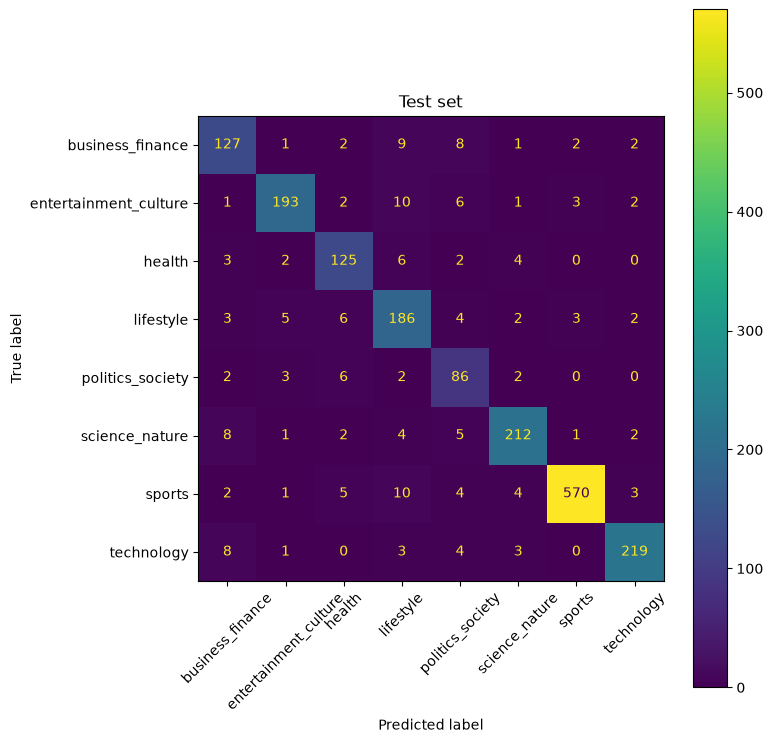

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_predicted,
    xticks_rotation=45,
    ax=ax,
)
ax.set_title("Test set")
fig.tight_layout()

## Terms the model relies on

For each class, these are the terms with the largest logistic-regression weights. They are a check that the TF–IDF features line up with the topic, not a full explanation of every prediction.

In [11]:
feature_names = model.named_steps["tfidf"].get_feature_names_out()
coefficients = model.named_steps["clf"].coef_

for class_index, label in enumerate(model.named_steps["clf"].classes_):
    top_indexes = coefficients[class_index].argsort()[-10:][::-1]
    terms = ", ".join(feature_names[index] for index in top_indexes)
    print(f"{label}: {terms}")

business_finance: job, financial, bitcoin, market, employers, crypto, nike, bank, jobs, social security
entertainment_culture: film, theatre, artist, album, cast, musical, music, actor, art, song
health: health, drug, mental health, mental, drugs, gambling, medical, medicines, patients, healthcare
lifestyle: fishing, fashion, restaurant, pageant, fish, miss, beauty, trail, tesla, road
politics_society: students, university, student, minister, education, academic, chancellor, universities, state, computer
science_nature: energy, brain, wildlife, scientists, study, animals, earth, researchers, animal, quantum
sports: season, team, golf, championship, champion, round, race, tour, players, win
technology: robots, robot, game, pokémon, apple, robotics, samsung, steam, games, galaxy


## A few test mistakes

Five test articles the model labeled incorrectly, with the original API topics they were tagged with. Several are label errors rather than model errors: the label comes from the topic feed the API listed the article under, and some feeds contain unrelated stories.

In [12]:
is_mistake = test_df["label"].to_numpy() != test_predicted
mistakes = test_df.loc[is_mistake].copy()
mistakes["predicted"] = test_predicted[is_mistake]

print(f"Test mistakes: {len(mistakes):,} of {len(test_df):,}")
with pd.option_context("display.max_colwidth", 90):
    display(mistakes[["title", "topics", "label", "predicted"]].head(8))

Test mistakes: 178 of 1,896


,title,topics,label,predicted
3935,"Official Photos of the Jordan Triangle ""Dongdan""",shopping,business_finance,lifestyle
8374,Bear Spray Demand Fuels Counterfeits and Safety Concerns,wildlife,science_nature,health
1277,Golfers sprung using AI to game timesheet system at elite clubs,golf,sports,technology
6338,Lucid Shares Sink After CFO Change Despite Higher Vehicle Deliveries,vehicles,lifestyle,business_finance
7004,Saving India's Universities,jobs,business_finance,politics_society
5048,"Faith Leaders Say End of TPS is a 'Moral Failure,' May Tear Families Apart",public health,health,politics_society
754,"India's oil dependence halves in 12 years as EV adoption, renewables curb consumption:...",energy,science_nature,business_finance
2966,Forecast update for crude oil -02-07-2026,energy,science_nature,business_finance


## Articles with more than one label

The 8-way model was trained only on single-label articles. The articles that belong to two or more groups were left out, and they are the harder, boundary cases. A prediction counts as a hit if it is one of the article's labels.

In [13]:
multi_df = pd.read_csv("data/clean/articles.csv")
multi_df = multi_df[multi_df["label"].str.contains("|", regex=False)].copy()
multi_df["text"] = multi_df["title"].fillna("").str.strip() + "\n" + multi_df["body"].fillna("").str.strip()

multi_predicted = model.predict(multi_df["text"])
hits = [prediction in labels.split("|") for prediction, labels in zip(multi_predicted, multi_df["label"])]
print(f"Multi-label articles: {len(multi_df):,}")
print(f"Prediction is one of the true labels: {sum(hits) / len(hits):.3f}")

Multi-label articles: 2,761
Prediction is one of the true labels: 0.928
